# Task 4 – Teil 8 und 9: Leitfragen, Ausblick und Fazit

## Aufgabenstellung

> **8. Leitfragen:** *Unter welchen Bedingungen und an welchen MV- oder LV-Bussen wird das Arbeits-Spannungsband von 0,90 bis 1,10 p.u. verletzt? Kann der regelbare Ortsnetztransformator die Spannungen mit diskreten Stufen zuverlässig begrenzen? – Wann und wo tritt eine Lastflussumkehr auf? Wie verändern sich dabei Spannungen, Betriebsmittelauslastungen und Anforderungen an die Regelung? – Durch welche Parametrierung wird Leitung 3-8 gezielt zuerst zum Engpass? Wie verändert eine begründete Kapazitätserhöhung die Belastung des Gesamtnetzes? – Wie wirken der 15-WEA-Windpark, das Ortsnetz mit fluktuierender Einspeisung und Last sowie die Großflächen-PV-Anlage jeweils einzeln und gemeinsam auf Spannungen, Lastflüsse, Engpässe und Verluste?*

> **9. Ausblick:** *Entwickeln Sie ein konzeptionelles Szenario, in dem die möglichst genaue Kenntnis des Netzzustands genutzt wird, um Speicher, Erzeuger und flexible Lasten so einzusetzen, dass ein Leistungs- und über einen festgelegten Zeitraum ein Energiegleichgewicht im betrachteten Netzgebiet unterstützt wird. […] Ein Regelalgorithmus, eine Optimierung oder ein zusätzlicher Simulationsnachweis wird in diesem Arbeitsauftrag nicht erwartet.*

> **Fazit:** *Fassen Sie im Fazit die wichtigsten Spannungs- und Lastflusseffekte, die Wirkung des Ortsnetztransformators, den Engpass an Line 3-8, die Kapazitätserhöhung und die Grenzen Ihrer Modellierung zusammen.*

| Anforderung | Umsetzung |
|---|---|
| Leitfrage Spannungsband und rONT | Abschnitt 1.1 |
| Leitfrage Lastflussumkehr | Abschnitt 1.2 |
| Leitfrage Line 3-8 | Abschnitt 1.3 |
| Leitfrage Szenarien einzeln und gemeinsam | Abschnitt 1.4 |
| Ausblick: Netzgebiet, Zeitraum, Zustandsgrößen | Abschnitt 2.1 |
| Ausblick: Zusammenwirken von Speicher, Erzeugern und Lasten | Abschnitt 2.2 |
| Ausblick: Leistungs- und Energiebilanz, Speicher, Austausch | Abschnitt 2.3 |
| Ausblick: Ziele, Randbedingungen, Zielkonflikte | Abschnitt 2.4 |
| Ausblick: Messungen, Prognosen, Zustandsschätzung | Abschnitt 2.5 |
| Fazit | Abschnitt 3 |

Die Zahlen in den Tabellen werden direkt aus den gespeicherten Zeitreihen von Teil 3 bis 5 berechnet (keine neuen Simulationen). Voraussetzung: Die Notebooks Teil 1 bis 5 wurden ausgeführt.

## Importe

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import regelung as rg
import bewertung as bw
import plots
import auswertung as aw
from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

GRUPPEN = {"Teil 3: ungeregelt": "w4_t3_", "Teil 3b: rONT-Regelung": "w4_t3r_", "Teil 4b: Wind": "w4_t4b_wind_",
           "Teil 4b: PV": "w4_t4b_pv_", "Teil 4b: Ortsnetz": "w4_t4b_on_", "Teil 4b: Wind + PV": "w4_t4b_wp_",
           "Teil 4/5: Wind + PV + Ortsnetz": "w4_t5_"}
SIMS = {g: {k: sim.loadSimulation(p + k) for k in sz.KEYS} for g, p in GRUPPEN.items()}
ONT = {"R": "LV Trafo R0-R1", "I": "LV Trafo I0-I1", "C": "LV Trafo C0-C1"}

## 1 Leitfragen

### 1.1 Spannungsband und regelbarer Ortsnetztransformator

*Unter welchen Bedingungen und an welchen MV- oder LV-Bussen wird das Arbeits-Spannungsband von 0,90 bis 1,10 p.u. verletzt? Kann der regelbare Ortsnetztransformator die Spannungen mit diskreten Stufen zuverlässig begrenzen?*

Stunden außerhalb des Planungsbands (0,95 … 1,05 pu) und der Arbeitsgrenzen (0,90 … 1,10 pu) je Ebene, für jede Gruppe der kleinste und größte Wert über die acht Schaltzustände, dazu die Stufenschritte der drei rONT:

In [3]:
zeilen = {}
for g, sims in SIMS.items():
    b = pd.DataFrame({k: aw.band_stunden(s) for k, s in sims.items()}).T
    stufen = pd.Series({k: int(rg.schaltvorgaenge(s).filter(like="Stufen").sum()) for k, s in sims.items()})
    z = {}
    for c in b.columns:
        if c.startswith("U min"):
            z[c] = b[c].min()
        elif c.startswith("U max"):
            z[c] = b[c].max()
        else:
            z[c] = f"{int(b[c].min())} … {int(b[c].max())}" if b[c].min() != b[c].max() else str(int(b[c].min()))
    z["Stufenschritte rONT (12 Wochen)"] = f"{stufen.min()} … {stufen.max()}"
    zeilen[g] = z
band = pd.DataFrame(zeilen).T
band

,Stunden < 0.95 MS,Stunden > 1.05 MS,Stunden < 0.9 MS,Stunden > 1.1 MS,U min MS [pu],U max MS [pu],Stunden < 0.95 NS,Stunden > 1.05 NS,Stunden < 0.9 NS,Stunden > 1.1 NS,U min NS [pu],U max NS [pu],Stufenschritte rONT (12 Wochen)
Teil 3: ungeregelt,0 … 9,0,0,0,0.948672,1.024345,450 … 473,0,0,0,0.921307,1.021062,0 … 0
Teil 3b: rONT-Regelung,0 … 9,0,0,0,0.948672,1.024345,0,0,0,0,0.950066,1.039135,192 … 196
Teil 4b: Wind,0,0,0,0,0.950828,1.030108,0,0,0,0,0.950004,1.040913,192 … 240
Teil 4b: PV,0 … 9,0,0,0,0.948672,1.024345,0,0,0,0,0.950066,1.039135,184 … 190
Teil 4b: Ortsnetz,0 … 9,0,0,0,0.948672,1.024345,0,0,0,0,0.95015,1.04998,250 … 256
Teil 4b: Wind + PV,0,0,0,0,0.950828,1.030108,0,0,0,0,0.950022,1.040913,190 … 224
Teil 4/5: Wind + PV + Ortsnetz,0,0,0,0,0.950828,1.030106,0,0,0,0,0.950006,1.04996,258 … 280


**Antwort:**

- **Im Normalbetrieb wird das Arbeitsband 0,90 … 1,10 pu an keinem MS- oder NS-Bus verletzt**, in keinem Szenario und keinem Schaltzustand (Teil 7, Abschnitt 4). Ohne Regelung unterschreitet das Ortsnetz aber das Planungsband: Am Ende des Wohngebiets (LV Bus R15) fällt die Spannung zur Abendspitze im Winter auf 0,923 pu, in 450 bis 473 Stunden unter 0,95 pu (Teil 3). Das MS-Netz liegt an Bus 11 in bis zu 9 Stunden knapp unter 0,95 pu (0,949 pu, Höchstlast bei offenem S1).
- **Verletzungen der Arbeitsgrenzen** treten nur unter Bedingungen auf, die verworfen oder als Grenzfall untersucht wurden: Anschluss des Ortsnetzes hinter Line 1-2 (Bus 2 bis 11, bis 0,85 pu im Wohngebiet, Teil 2), Windpark in den Abgängen (bis 1,23 pu, Teil 4a), viele PV-Haushalte (Variante Zukunft, bis 1,20 pu am Strangende R15, Teil 4b), Windpark mit untererregter Blindleistung (0,90 pu an Bus 11, Teil 4b) und Ausfall eines 110/20-kV-Trafos mit Kupplung über S1 (0,40 bis 1,25 pu, Teil 5).
- **Kann der rONT die Spannung zuverlässig begrenzen?** Ja, solange der Stellbereich reicht. Mit ±2 Stufen à 2,5 % hält er das Ortsnetz in allen Schaltzuständen im Planungsband: abends hebt er an, mittags bei Rückspeisung senkt er ab (Teil 3b, 4b, 5). Der Wohngebiet-rONT braucht dafür 150 bis 170 Stufenschritte in 12 Wochen, meist genügt eine Stufe. **Grenzen:** Er wirkt nur auf sein eigenes Teilnetz und verschiebt alle Busse dort gleich. Er kann den Unterschied zwischen Sammelschiene und Strangende nicht verkleinern. Bei großer Rückspeisung (Variante Zukunft) reicht auch Stufe +2 nicht, und auf das MS-Netz hat er keinen Einfluss.

### 1.2 Lastflussumkehr

*Wann und wo tritt eine Lastflussumkehr auf? Wie verändern sich dabei Spannungen, Betriebsmittelauslastungen und Anforderungen an die Regelung?*

Stunden mit umgekehrtem Wirkleistungsfluss (Schwelle 1 kW) und größte Rückspeiseleistung an den Netzkuppelstellen, im Normalschaltzustand (S1–S3 offen):

In [4]:
def umkehr(s):
    r = s.results
    ok = r.converged.astype(bool)
    reihen = {"110-kV-Netz (ext_grid)": r.ext_grid_p_mw[ok].sum(axis=1), "Trafo 0-1": r.trafo_p_mw[ok]["Trafo 0-1"],
              "Trafo 0-12": r.trafo_p_mw[ok]["Trafo 0-12"]}
    reihen |= {f"Ortsnetztrafo {x}": r.trafo_p_mw[ok][t] for x, t in ONT.items()}
    return {(ort, g): v for ort, p in reihen.items() for g, v in
            (("Stunden", int((p < -0.001).sum())), ("max. [MW]", max(0.0, -p.min())))}

umk = pd.DataFrame({g: umkehr(sims["000"]) for g, sims in SIMS.items()}).T
umk.columns = pd.MultiIndex.from_tuples(umk.columns)
plots.table(umk, decimals=3)

**Antwort:**

- **MS-Netz:** Lastflussumkehr tritt an Trafo 0-1 (615 Stunden, bis 22,5 MW) und an der Netzkuppelstelle zum 110-kV-Netz (266 Stunden, bis 16,1 MW) auf. Auslöser ist der Windpark: Trafo 0-1 kehrt sich um, sobald der Wind mehr liefert, als Abgang 1 verbraucht, das 110-kV-Netz, sobald alle Erzeuger zusammen mehr liefern, als das ganze Netz verbraucht. Das passiert vor allem nachts und am Wochenende bei Starkwind. Die PV-Freiflächenanlage allein führt nie zur Umkehr. Mit geschlossenem S1 kehren sich zusätzlich die Kupplung Line 14-8 und Abgang 2 um (bis 676 Stunden), weil Windstrom durch Abgang 1 und über S1 zu Trafo 0-12 fließt (Teil 5).
- **Ortsnetz:** Im Wohngebiet kehren sich Ortsnetztrafo R und alle Leitungen in rund 390 Stunden um (bis 0,45 MW), mittags von März bis September, wenn die Heimspeicher voll sind.
- **Folgen für die Spannung:** Mit der Umkehr steigt die Spannung zum Einspeisepunkt hin statt zu fallen. Im MS-Netz bleibt das klein (höchstens 1,030 pu), weil die Erzeuger an den Sammelschienen hängen. Im Wohngebiet steigt die Spannung am Strangende bis an 1,05 pu.
- **Folgen für die Auslastung:** Die Auslastung hängt vom Betrag des Stroms ab, nicht von der Richtung. Trafo 0-1 ist bei Starkwind höher ausgelastet als bei Höchstlast ohne Erzeuger (88,5 % gegenüber 82,7 %). Mit S1 erreicht Line 1-2 bei Starkwind 99,6 %.
- **Folgen für die Regelung:** Der Wohngebiet-rONT muss jetzt in beide Richtungen regeln: in 140 Stunden nach unten gegen Überspannung, abends nach oben gegen Unterspannung. Ein Regler nur für Unterspannung oder eine feste Stufe würde nicht mehr reichen. Im MS-Netz gibt es keinen Stufenschalter; dort bleibt nur der Betrieb mit offenem S1.

### 1.3 Line 3-8: Engpass und Kapazitätserhöhung

*Durch welche Parametrierung wird Leitung 3-8 gezielt zuerst zum Engpass? Wie verändert eine begründete Kapazitätserhöhung die Belastung des Gesamtnetzes?*

**Antwort (Teil 6):**

- **Parametrierung:** Eine Laststeigerung allein macht Line 3-8 nie zum ersten Engpass, weil die vorgelagerten Kabel Line 1-2 und 2-3 immer die Summe aller Lasten dahinter tragen. Line 3-8 wird erst durch eine **Einspeisung an Bus 8** zum Engpass, weil diese Leistung zuerst über Line 3-8 zurückfließt. Im Referenznetz (`with_der=False`, 60 % Last, alle Schalter offen) erreicht Line 3-8 bei **6,49 MW** Einspeisung an Bus 8 ihre Grenze von 145 A (100 %), während Line 2-3 und 1-2 bei etwa 76 % und alle anderen Leitungen unter 20 % liegen. Die Einspeisung wurde linear gesteigert, die Stromgrenze nicht verändert.
- **Kapazitätserhöhung:** Ein Ersatz durch ein NA2XS2Y 1×70 12/20 kV (oder ein Parallelkabel) hebt die aufnehmbare Leistung um etwa 1,4 MW (+21 %). Größere Querschnitte bringen nichts mehr, weil dann **Line 2-3 und 1-2 zum Engpass werden**. Die Spannungen ändern sich kaum, die Verluste sinken leicht.
- **Wirkung auf das Gesamtnetz:** Der Engpass wird nicht beseitigt, sondern verlagert. In vermaschten Schaltzuständen zieht die stärkere Leitung zusätzlich Leistung an. Für mehr Einspeisung an Bus 8 müsste der ganze Weg bis Bus 1 verstärkt werden (7,2 km statt 1,3 km Kabel), oder die Einspeisung müsste begrenzt bzw. direkt an der Umspannwerks-Sammelschiene angeschlossen werden.

### 1.4 Windpark, Ortsnetz und PV-Anlage einzeln und gemeinsam

*Wie wirken der 15-WEA-Windpark, das Ortsnetz mit fluktuierender Einspeisung und Last sowie die Großflächen-PV-Anlage jeweils einzeln und gemeinsam auf Spannungen, Lastflüsse, Engpässe und Verluste?*

Kennwerte im Normalschaltzustand (12 Wochen, rONT-Regelung aktiv), Baseline ist das ausgelegte Netz mit rONT-Regelung aus Teil 3b:

In [5]:
auswahl = {"Baseline (Teil 3b)": SIMS["Teil 3b: rONT-Regelung"]["000"]} | {
    g.split(": ")[1]: SIMS[g]["000"] for g in GRUPPEN if g.startswith("Teil 4")}
werte, orte = bw.kennwerte(auswahl)
spalten = [c for c in ["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Leitung max MS [%]", "Leitung max NS [%]",
                       "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Verluste [MWh]", "Stunden Rückspeisung 110 kV",
                       "max. Rückspeisung 110 kV [MW]"] if c in werte.columns]
plots.table(werte[spalten].astype(float), decimals=3)

,U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Verluste [MWh],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Baseline (Teil 3b),0.949,1.024,0.950,1.027,78.638,71.073,82.694,66.838,162.797,0.000,0.000
Wind,0.951,1.025,0.950,1.027,78.491,71.073,88.512,66.838,154.884,233.000,16.100
PV,0.949,1.024,0.950,1.027,78.638,71.073,82.694,66.838,159.514,0.000,0.000
Ortsnetz,0.949,1.024,0.950,1.050,78.638,78.615,82.694,75.449,161.292,0.000,0.000
Wind + PV,0.951,1.025,0.950,1.027,78.491,71.073,88.512,66.838,151.602,263.000,16.100
Wind + PV + Ortsnetz,0.951,1.025,0.950,1.050,78.491,78.498,88.512,75.331,150.223,266.000,16.108


**Antwort:**

| | Spannungen | Lastflüsse | Engpässe | Verluste |
|---|---|---|---|---|
| **Windpark (Bus 1)** | MS +0,2 Prozentpunkte (U min 0,949 → 0,951 pu) | Rückspeisung ins 110-kV-Netz in 233 h, bis 16,1 MW | Trafo 0-1 88,5 % (statt 82,7 %); mit S1 MS-Leitungen bis 99,6 % | −7,9 MWh (offen), +61 MWh (S1 zu) |
| **PV-Anlage (Bus 12)** | praktisch keine Änderung | keine Umkehr, Bezug von Abgang 2 sinkt | keine | −3,3 MWh (offen), +3,7 MWh (S1 zu) |
| **Ortsnetz mit PV-Haushalten** | NS bis 1,050 pu (statt 1,027) | Umkehr im Wohngebiet in 390 h, bis 0,45 MW | Ortsnetztrafo R 75 % (statt 67 %), NS-Leitungen 78 % (statt 71 %) | −1,5 MWh |
| **alle zusammen** | wie die Summe der Einzelwirkungen | 266 h Rückspeisung ins 110-kV-Netz | wie Windpark und Ortsnetz | −12,6 MWh (−8 %) |

- **Einzeln:** Jeder Erzeuger wirkt vor allem dort, wo er angeschlossen ist. Windpark und PV-Anlage an den Trafo-Sammelschienen ändern Trafoauslastung und Austausch mit dem 110-kV-Netz, aber kaum Spannungen und Leitungsauslastungen in den Abgängen. Die PV-Haushalte wirken nur im Wohngebiet.
- **Gemeinsam:** Die Wirkungen addieren sich fast genau, weil die Erzeuger an verschiedenen Stellen einspeisen. Nur die Rückspeisung ins 110-kV-Netz wächst überproportional (233 → 266 Stunden), weil PV und Wind zusammen die Last häufiger übersteigen.
- **Entscheidend ist der Schaltzustand:** Mit geschlossenem S1 kehrt sich das Bild beim Windpark um: Die Verluste steigen statt zu sinken, und die MS-Leitungen werden fast voll ausgelastet.

## 2 Ausblick: Smart-Grid-Anwendung für das Wohngebiet

Das Konzept wird für das Wohngebiet (Teilnetz R des Ortsnetzes) entwickelt, weil dort mit den PV-Haushalten und Heimspeichern alle drei Arten von Flexibilität schon vorhanden sind und die Rückspeisung in Teil 4b und 5 auftritt. Als Datengrundlage dient die Zeitreihe am Ende von Teil 4 (`w4_t5_000`, S1–S3 offen) als idealisierte, vollständige Kenntnis des Netzzustands.

### 2.1 Netzgebiet, Zeitraum und Zustandsgrößen

- **Netzgebiet:** das Wohngebiet am Ortsnetztrafo R (Teilnetz R des CIGRE-LV-Netzes, Bus R0 bis R18) mit den Haushaltslasten, den PV-Anlagen der Haushalte und den Heimspeichern. Die Grenze des Gebiets ist der Ortsnetztrafo R; über ihn wird Leistung mit dem MS-Netz ausgetauscht.
- **Zeitraum:** Leistungsbilanz in jeder Stunde (Auflösung der Simulation); Energiebilanz über einen Tag, weil sich PV-Überschuss am Mittag und Bedarf am Abend und in der Nacht im Tagesrhythmus abwechseln und ein Heimspeicher etwa einen Tag überbrücken kann. Zur Einordnung zusätzlich je typische Woche und über alle 12 Wochen.
- **Relevante Zustandsgrößen:**

| Größe | wofür | in der Simulation |
|---|---|---|
| Spannung an den Strangenden (R11, R15 bis R18) und an der Sammelschiene R1 | Spannungsband 0,95 … 1,05 pu; Überspannung bei Rückspeisung, Unterspannung bei Abendspitze | `vm_pu` |
| Wirkleistung am Ortsnetztrafo R (`p_hv_mw`) | Austausch mit dem MS-Netz, Richtung des Flusses, Auslastung des Trafos | `trafo_p_mw`, `trafo_loading` |
| Auslastung der LV-Kabel (vor allem der ersten Abschnitte R1-R2, R2-R3) | thermische Engpässe | `line_loading` |
| PV-Erzeugung und Verbrauch je Bus | lokaler Überschuss oder Bedarf | `sgen_p_mw`, `load_p_mw` |
| Ladezustand und Leistung der Speicher | verfügbare Flexibilität | `storage_soc_percent`, `storage_p_mw` |
| Netzverluste | Teil der Leistungsbilanz | `line_pl_mw`, `trafo_pl_mw` |
| Stufenstellung des rONT | Reserve der Spannungsregelung | `tap_pos` |

**Heutiger Zustand ohne Koordination:** Leistungsbilanz des Wohngebiets in einer Juniwoche. Der Speicher arbeitet nur für den Eigenverbrauch seines Haushalts (Teil 4b); der Ortsnetztrafo zeigt den Austausch mit dem MS-Netz.

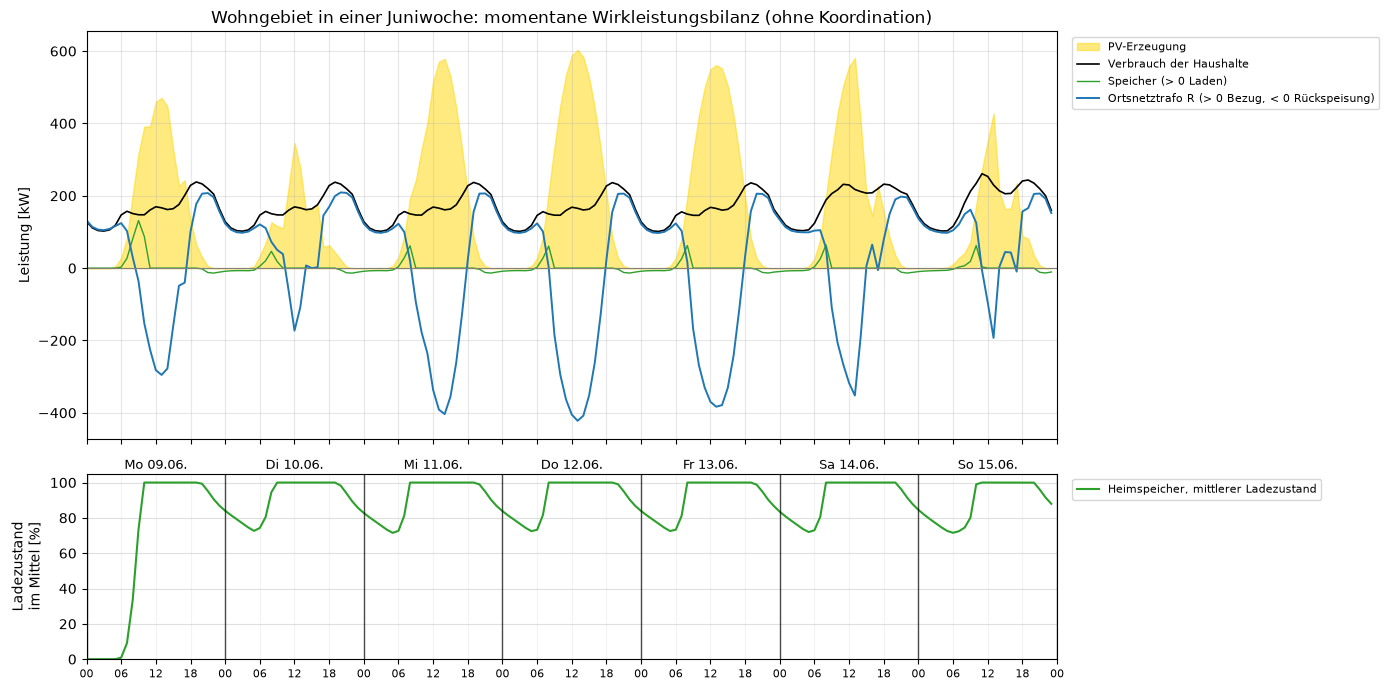

In [6]:
s = SIMS["Teil 4/5: Wind + PV + Ortsnetz"]["000"]
r = s.results
def spalten_mit(df, prefix):
    return [c for c in df.columns if c.startswith(prefix)]

def wohngebiet(r):
    ok = r.converged.astype(bool)
    last = r.load_p_mw[ok][spalten_mit(r.load_p_mw, "LV Load R")].sum(axis=1)
    pv = r.sgen_p_mw[ok][spalten_mit(r.sgen_p_mw, "LV PV")].sum(axis=1)
    sto = r.storage_p_mw[ok][spalten_mit(r.storage_p_mw, "LV Speicher R")].sum(axis=1)
    verl = r.line_pl_mw[ok][spalten_mit(r.line_pl_mw, "LV Line R")].sum(axis=1) + r.trafo_pl_mw[ok][ONT["R"]]
    trafo = r.trafo_p_mw[ok][ONT["R"]]
    soc = r.storage_soc_percent[ok][spalten_mit(r.storage_soc_percent, "LV Speicher R")].mean(axis=1)
    return pd.DataFrame({"Last": last, "PV": pv, "Speicher": sto, "Verluste": verl, "Trafo": trafo, "SOC": soc})

wg = wohngebiet(r)
idx = r.info.index[r.info["month"] == "JUNE"]
w = wg.loc[wg.index.intersection(idx)] * [1000, 1000, 1000, 1000, 1000, 1]
x = w.index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
axes[0].fill_between(x, w["PV"], color="gold", alpha=0.5, label="PV-Erzeugung")
axes[0].plot(x, w["Last"], color="black", lw=1.2, label="Verbrauch der Haushalte")
axes[0].plot(x, w["Speicher"], color="tab:green", lw=1, label="Speicher (> 0 Laden)")
axes[0].plot(x, w["Trafo"], color="tab:blue", lw=1.4, label="Ortsnetztrafo R (> 0 Bezug, < 0 Rückspeisung)")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Leistung [kW]")
axes[0].set_title("Wohngebiet in einer Juniwoche: momentane Wirkleistungsbilanz (ohne Koordination)")
axes[1].plot(x, w["SOC"], color="tab:green", label="Heimspeicher, mittlerer Ladezustand")
axes[1].set_ylabel("Ladezustand\nim Mittel [%]")
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plots.week_axis(axes[1], w.index)
plt.tight_layout()
plt.show()

**Bilanzprüfung:** Für jede Stunde gilt im Wohngebiet `Trafo = Last + Speicher − PV + Verluste` (Verbraucherzählpfeilsystem). Über einen Zeitraum wird daraus die Energiebilanz; beim Speicher kommen die Wandlungsverluste hinzu (η = 0,95 je Richtung):

In [7]:
rest = wg["Trafo"] - (wg["Last"] + wg["Speicher"] - wg["PV"] + wg["Verluste"])
print(f"größte Abweichung der momentanen Bilanz: {1e3 * rest.abs().max():.3f} kW")

def energiebilanz(df):
    return {"Verbrauch [MWh]": df["Last"].sum(), "PV-Erzeugung [MWh]": df["PV"].sum(),
            "Speicher geladen [MWh]": df["Speicher"].clip(lower=0).sum(), "Speicher entladen [MWh]": -df["Speicher"].clip(upper=0).sum(),
            "Netzverluste Wohngebiet [MWh]": df["Verluste"].sum(),
            "Bezug aus MS-Netz [MWh]": df["Trafo"].clip(lower=0).sum(), "Rückspeisung ins MS-Netz [MWh]": -df["Trafo"].clip(upper=0).sum(),
            "Stunden Rückspeisung": int((df["Trafo"] < -0.001).sum()),
            "Eigenversorgung [%]": 100 * (1 - df["Trafo"].clip(lower=0).sum() / df["Last"].sum())}

monat = r.info.loc[wg.index, "month"]
eb = pd.DataFrame({Month[m].label: energiebilanz(wg[monat == m]) for m in dict.fromkeys(monat)}).T
eb.loc["12 Wochen"] = energiebilanz(wg)
plots.table(eb, decimals=2, int_cols=["Stunden Rückspeisung"])

größte Abweichung der momentanen Bilanz: 0.000 kW


,Verbrauch [MWh],PV-Erzeugung [MWh],Speicher geladen [MWh],Speicher entladen [MWh],Netzverluste Wohngebiet [MWh],Bezug aus MS-Netz [MWh],Rückspeisung ins MS-Netz [MWh],Stunden Rückspeisung,Eigenversorgung [%]
Januar,38.47,4.46,1.21,1.07,0.98,35.13,-0.00,0,8.68
Februar,37.76,10.25,1.70,1.38,0.88,30.12,1.41,10,20.23
März,34.67,26.91,1.48,1.14,0.90,20.43,11.43,51,41.07
April,32.71,28.37,1.21,0.86,0.91,18.52,12.93,54,43.37
Mai,28.70,23.96,0.95,0.60,0.72,15.77,9.96,49,45.06
Juni,28.29,26.56,0.88,0.53,0.73,14.21,11.39,50,49.77
Juli,28.20,22.46,0.93,0.59,0.62,14.65,7.94,50,48.07
August,27.55,25.93,0.98,0.63,0.72,14.18,11.49,57,48.54
September,28.32,17.42,1.16,0.82,0.64,17.97,6.10,36,36.54
Oktober,31.77,11.14,1.46,1.11,0.66,22.88,1.24,14,27.99


**Befund (ohne Koordination):**

- Die momentane Bilanz geht in jeder Stunde auf. Über die 12 Wochen erzeugen die PV-Anlagen 214 MWh, das Wohngebiet verbraucht 390 MWh. Es bezieht 264 MWh aus dem MS-Netz und speist 76 MWh zurück. Nur 32 % des Verbrauchs werden im Gebiet selbst gedeckt.
- Die Speicher laden 15,1 MWh und geben 11,4 MWh ab; die Differenz (3,7 MWh, etwa 24 %) sind Wandlungsverluste und der Ladezustand am Wochenende. Die Speicher werden damit kaum genutzt: 314 kWh Kapazität werden im Mittel nicht einmal einmal am Tag voll durchgeladen.
- **Sommer und Winter unterscheiden sich stark:** Im Juni deckt das Gebiet die Hälfte seines Verbrauchs selbst und speist trotzdem 11 MWh zurück. Im Januar erzeugen die PV-Anlagen nur 12 % des Verbrauchs, und es gibt keine Rückspeisung. Ein Energiegleichgewicht über eine Woche ist im Sommer fast erreicht (Juni: 26,6 MWh PV gegenüber 28,3 MWh Verbrauch), im Winter nicht.
- **Folgerung für die Koordination:** Im Sommer liegt das Problem in der Verteilung über den Tag: mittags zu viel, abends zu wenig. Das lässt sich mit Speichern und verschiebbaren Lasten ausgleichen. Im Winter fehlt Energie; dort kann die Koordination nur die Abendspitze glätten.

### 2.2 Zusammenwirken von Speicher, Erzeugern und flexiblen Lasten

Das Konzept ist eine Koordinationsfunktion beim Netzbetreiber oder einem Energiemanager für das Wohngebiet. Sie bekommt jede Viertelstunde den Netzzustand und gibt den Anlagen Sollwerte vor. Die Reihenfolge der Maßnahmen folgt der Idee, zuerst das zu nutzen, was nichts kostet und keine Energie verschwendet. Abregelung und Eingriffe beim Kunden kommen zuletzt [40], [41]:

1. **Speicher netzdienlich laden.** Heute laden die Heimspeicher morgens, sobald PV-Überschuss da ist, und sind zur Mittagsspitze schon voll (Abbildung oben). Mit Prognose laden sie erst, wenn die Rückspeisung am Ortsnetztrafo eine Schwelle überschreitet, und nehmen so die Spitze auf statt der Morgenstunden. Der Eigenverbrauch des Haushalts bleibt fast gleich, die Rückspeisespitze sinkt.
2. **Flexible Lasten verschieben.** Wärmepumpen (mit Wärmespeicher) und Ladepunkte für Elektroautos verschieben ihren Bezug in die Stunden mit PV-Überschuss. Abends, wenn die Spannung an den Strangenden am niedrigsten ist, beziehen sie weniger. In Deutschland ist dafür § 14a EnWG der Rahmen: Der Netzbetreiber darf steuerbare Verbrauchseinrichtungen bei drohender Überlastung auf eine Mindestleistung dimmen [42].
3. **Speicher entladen in der Abendspitze.** Der Speicher deckt den Abendbedarf und senkt so den Bezug über den Ortsnetztrafo und den Spannungsfall an den Strangenden.
4. **Blindleistung der Wechselrichter.** PV-Wechselrichter können bei hoher Spannung Blindleistung beziehen (cos φ(P)- oder Q(U)-Kennlinie nach VDE-AR-N 4105 [30]). Im Kabelnetz mit großem R/X ist die Wirkung klein (Teil 4b, Abschnitt 5), aber ohne Energieverlust für den Kunden.
5. **rONT.** Der Stufenschalter verschiebt die Spannung des ganzen Teilnetzes und bleibt die Grundregelung (Teil 3b). Die Koordination sorgt dafür, dass er nicht dauernd an der Stellgrenze steht.
6. **Abregelung als letztes Mittel.** Erst wenn Speicher voll und Lasten ausgeschöpft sind und die Spannung trotzdem über 1,05 pu steigt, wird die PV-Einspeisung begrenzt (Spitzenkappung, höchstens 3 % der Jahresenergie nach EnWG § 11 Abs. 2 [39]).

### 2.3 Leistungsbilanz und Energiegleichgewicht

- **Momentane Wirkleistungsbilanz** (jede Stunde): P_Trafo = P_Last + P_Speicher − P_PV + P_Verluste. P_Trafo ist der Austausch mit dem MS-Netz (> 0 Bezug, < 0 Rückspeisung), P_Speicher ist > 0 beim Laden. Die Bilanz geht in der Simulation in jeder Stunde auf (Prüfung oben). Ziel der Koordination ist nicht P_Trafo = 0 in jeder Stunde, sondern ein Austausch innerhalb fester Grenzen (z. B. Trafoauslastung, Rückspeisegrenze).
- **Energiebilanz über den Zeitraum** (Tag, Woche): Σ Bezug − Σ Rückspeisung = Σ Verbrauch + Σ Verluste − Σ PV + Σ Speicherverluste + (Ladezustand am Ende − Ladezustand am Anfang). Ein Energiegleichgewicht im Gebiet heißt: Über den Tag deckt die PV-Erzeugung den Verbrauch einschließlich der Verluste. Dann ist der Nettoaustausch null, auch wenn stundenweise Leistung fließt.
- **Speicher:** Ladezustand zwischen 0 und 100 %, Lade- und Entladeleistung begrenzt (hier 0,59 kW je kWh), Wirkungsgrad 0,95 je Richtung, also etwa 90 % über einen Zyklus. Jede gespeicherte kWh kostet etwa 0,1 kWh Verluste. Ein voller Speicher kann keinen Überschuss mehr aufnehmen, ein leerer keinen Bedarf decken.
- **Wann der Austausch mit dem MS-Netz bleibt:** Im Winter erzeugen die PV-Anlagen viel weniger, als das Wohngebiet verbraucht. Der Bezug lässt sich durch Speicher nur zeitlich verschieben, nicht vermeiden (Tabelle oben). Im Sommer übersteigt die Erzeugung an sonnigen Tagen den Tagesverbrauch, und der Überschuss muss ins MS-Netz fließen, wenn er nicht abgeregelt werden soll. Ein Ausgleich über Wochen oder Jahreszeiten ist mit Heimspeichern nicht möglich.

### 2.4 Ziele, Randbedingungen und Zielkonflikte

| Ziel | Messgröße | Randbedingung |
|---|---|---|
| keine Spannungsbandverletzung | Stunden außerhalb 0,95 … 1,05 pu (Planungsband) an allen Bussen | 0,90 … 1,10 pu darf nie verletzt werden |
| keine thermischen Engpässe | Auslastung Ortsnetztrafo und LV-Kabel | höchstens 100 % |
| begrenzter Austausch mit dem MS-Netz | größte Rückspeisung und größter Bezug am Ortsnetztrafo, Stunden mit Rückspeisung | z. B. Rückspeisung höchstens so groß wie der Bezug zur Abendspitze |
| geringe Abregelung | abgeregelte Energie | höchstens 3 % der Jahresenergie [39] |
| geringe Speicherbeanspruchung | Vollzyklen je Jahr, Zeit bei 100 % Ladezustand | Lebensdauer, Garantiebedingungen |
| Kundennutzen | Eigenverbrauch, Stromkosten | Kunde muss zustimmen (Anreiz, § 14a EnWG [42]) |

**Zielkonflikte:**

- **Eigenverbrauch gegen Netzentlastung:** Der Kunde will den Speicher so früh wie möglich füllen. Das Netz braucht den leeren Speicher zur Mittagsspitze. Bleibt die Sonne aus, ist der Speicher abends nicht voll.
- **Abregelung gegen Speicherverluste:** Eine kWh einzuspeichern kostet etwa 10 % Verluste, eine kWh abzuregeln kostet 100 %. Kurze Spitzen sind deshalb oft günstiger abzuregeln als einen zusätzlichen Speicher zu bauen.
- **Lokales Gleichgewicht gegen Gesamtnetz:** Ein Wohngebiet, das seine Rückspeisung selbst aufnimmt, entlastet sein Ortsnetz. Für das MS-Netz kann dieselbe Energie aber gerade dann nützlich sein, wenn an anderer Stelle Last anliegt. Die Koordination muss über die Ebenen hinweg abgestimmt werden.
- **Speicherbeanspruchung gegen Regelgüte:** Häufiges Umschalten zwischen Laden und Entladen glättet den Austausch, erhöht aber die Zyklenzahl.

### 2.5 Messungen, Prognosen und Zustandsschätzung

Die Simulation kennt Spannung und Fluss an jedem Bus in jeder Stunde. Im realen Ortsnetz ist das nicht so: Gemessen wird oft nur am Ortsnetztrafo, und Hausanschlüsse liefern Zählerstände, aber keine Spannungen in Echtzeit. Für eine Umsetzung wären nötig:

- **Messungen:** Strom und Spannung an der NS-Sammelschiene des Ortsnetztrafos; Spannungsmessung an den Strangenden (wo die Grenzen zuerst erreicht werden, Teil 3b); Messwerte von intelligenten Messsystemen (Smart-Meter-Gateway) der Haushalte mit PV, Speicher, Wärmepumpe oder Ladepunkt.
- **Kommunikation:** Sollwerte an Speicher, Wechselrichter und steuerbare Verbrauchseinrichtungen. Nach § 14a EnWG läuft die Steuerung über das Smart-Meter-Gateway [42].
- **Netzzustandsschätzung:** Aus wenigen Messungen, Netzmodell (Impedanzen aus der Netzdokumentation) und Ersatzwerten (Standardlastprofile, PV-Erzeugung aus Wetterdaten) werden die Spannungen und Flüsse an allen Bussen geschätzt. Genau dafür lassen sich die Lastflussmodelle aus diesem Arbeitsauftrag nutzen.
- **Prognosen:** PV-Erzeugung aus der Wetterprognose und Verbrauch aus Lastprofil und Vortageswerten für die nächsten Stunden. Nur mit Prognose kann ein Speicher bis zur Mittagsspitze leer bleiben.

Die Koordination selbst (Regelalgorithmus, Optimierung) ist nicht Teil dieses Arbeitsauftrags und wird im finalen Arbeitsauftrag als eigene Funktion für das hier aufgebaute Netz ergänzt.

## 3 Fazit

**Spannungs- und Lastflusseffekte:**

- Das CIGRE-MV-Netz ist im Normalbetrieb mit offenen Trennschaltern spannungsstabil: Alle Busse bleiben in allen Szenarien innerhalb von 0,90 … 1,10 pu. Kritisch ist Abgang 1 mit langen Kabeln (U min 0,949 pu an Bus 11 bei Höchstlast) und Trafo 0-1 (bis 88,5 %).
- Das CIGRE-LV-Ortsnetz musste ausgelegt werden (größere Ortsnetztrafos, stärkere Gewerbe-Freileitung) und wurde an Bus 12 angeschlossen, die Sammelschiene mit der größten Reserve (Teil 2, 3).
- Windpark (30 MW) und PV-Anlage (10 MWp) sind nur an den Trafo-Sammelschienen anschließbar. Dort ändern sie die Spannung kaum, kehren aber den Fluss an Trafo 0-1 (615 h) und ins 110-kV-Netz (266 h, bis 16 MW) um. PV-Haushalte kehren den Fluss im Wohngebiet um (390 h) und heben die Spannung dort bis an das Planungsband.
- S1 entlastet ohne Erzeuger Abgang 1 und senkt die Verluste um 21 %. Mit Windpark führt S1 zu Lastflussumkehr auf der Kupplung, bis 99,6 % Leitungsauslastung und höheren Verlusten. S2 und S3 ändern fast nichts.

**Wirkung des Ortsnetztransformators:** Drei unabhängige rONT (±2 × 2,5 %, Messung an den Strangenden) halten das Ortsnetz in allen Schaltzuständen und Szenarien im Planungsband 0,95 … 1,05 pu. Ohne Regelung lag es in 450 Stunden darunter. Mit PV-Haushalten regelt der Wohngebiet-rONT in beide Richtungen. Bei viel mehr PV (Variante Zukunft) reicht der Stellbereich nicht mehr: Trafo und Kabel werden überlastet, die Spannung steigt bis 1,20 pu.

**Engpass an Line 3-8 und Kapazitätserhöhung:** Line 3-8 wird nur durch eine Einspeisung an Bus 8 zum ersten Engpass (6,49 MW bei 60 % Last). Ein stärkeres Kabel erhöht die aufnehmbare Leistung um 21 %, verlagert den Engpass aber auf Line 2-3 und 1-2.

**(n-1):** Leitungsausfälle lassen sich mit genau einem Trennschalter vollständig wiederversorgen, auch mit Erzeugern. Den Ausfall eines 110/20-kV-Trafos kann S1 nicht auffangen.

**Grenzen der Modellierung:** symmetrischer, stationärer Lastfluss in Stundenwerten; 12 typische Wochen statt eines Jahres; Standardlastprofile ohne Spitzen einzelner Kunden; idealisierte Regelung ohne Totzeit; starres 110-kV-Netz; Heimspeicher mit festem Eigenverbrauchsfahrplan; CIGRE-Parameter, die teils von realen Betriebsmitteln abweichen; kein Ortsnetzprofil aus W2 (Teil 7, Abschnitt 8).

**Ausblick:** Die Netzzustandsgrößen aus dieser Arbeit reichen aus, um Speicher, flexible Lasten und Wechselrichter netzdienlich zu koordinieren (Abschnitt 2). Der größte Hebel im Wohngebiet ist, die Heimspeicher erst zur Mittagsspitze zu laden. Das wird im finalen Arbeitsauftrag als eigene Funktion umgesetzt.

### Quellen

Nummern wie im zentralen Quellenverzeichnis (`Task4-Datengrundlage.ipynb`, Abschnitt 3).

[30] VDE-AR-N 4105, „Erzeugungsanlagen am Niederspannungsnetz – Technische Mindestanforderungen für Anschluss und Parallelbetrieb von Erzeugungsanlagen am Niederspannungsnetz“, Berlin: VDE Verlag, 2018.

[39] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 11 Abs. 2 (Spitzenkappung). Online: https://www.gesetze-im-internet.de/enwg_2005/__11.html

[40] V. Ilea, C. Bovo, D. Falabretti, M. Merlo, C. Arrigoni, R. Bonera und M. Rodolfi, „Voltage Control Methodologies in Active Distribution Networks“, *Energies*, Bd. 13, Nr. 12, Art. 3293, 2020, doi: 10.3390/en13123293.

[41] S. Huang, Q. Wu, Z. Liu und A. H. Nielsen, „Review of Congestion Management Methods for Distribution Networks with High Penetration of Distributed Energy Resources“, in *Proc. IEEE PES ISGT Europe*, Istanbul, 2014, S. 1–6, doi: 10.1109/ISGTEurope.2014.7028811.

[42] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 14a (netzorientierte Steuerung von steuerbaren Verbrauchseinrichtungen und steuerbaren Netzanschlüssen). Online: https://www.gesetze-im-internet.de/enwg_2005/__14a.html
